# Active subspace of a soil-moisture calibration: CMF van Genuchten–Mualem parameters (SPOTPY runs)

Stored data from

T. Houska, P. Kraft, A. Chamorro-Chavez and L. Breuer, *SPOTting Model Parameters Using a Ready-Made
Python Package*, PLOS ONE 10(12):e0145180, 2015.
[doi:10.1371/journal.pone.0145180](https://doi.org/10.1371/journal.pone.0145180)

1 Institute for Landscape Ecology and Resources Management, Research Centre for BioSystems, Land Use and
Nutrition (IFZ), Justus Liebig University, Giessen, Germany; 2 Centre for International Development and
Environmental Research, Justus Liebig University, Giessen, Germany. (Houska 1; Kraft 1; Chamorro-Chavez 1;
Breuer 1,2.)

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 615                        # the only seed: every bootstrap below draws from it
t_start = time.perf_counter()
warnings.simplefilter('ignore', ac.ValidityWarning)
names = ['alpha', 'n', 'ksat', 'porosity']
labels = [r'$\alpha$', r'$n$', r'$K_{sat}$', r'$\phi$']

## Summary

Houska et al. calibrated four van Genuchten–Mualem soil parameters of a one-dimensional CMF (Richards
equation) soil column against a year of daily topsoil soil moisture at the Linden FACE grassland site, and
deposited every run of their Monte Carlo (MC) and Latin hypercube (LHS) samplers with its RMSE. On the 9,972
valid MC runs (draws from the normal prior), the global quadratic estimator (QPHD) gives $\lambda_1/\lambda_2 =
108.0$ (95 % bootstrap interval 50.3–256.4) with a leading direction dominated by the shape parameter $n$
(+0.79) and the porosity $\phi$ (−0.566). That gap describes a quadratic with leave-one-out $R^2$ of only 0.8338,
which cannot follow the steep rise of the RMSE as $\alpha \to 0$: the 36 runs with $\alpha < 0.05$ 1/cm, 0.0036
of the runs, hold 0.0635 of the sum of squares, and a second, almost pure-$\alpha$ direction describes them
(LOO $R^2$ 0.8913 for a polynomial in one active variable, 0.9609 in two). The RMSE is one-dimensional for the
bulk of the prior, where it is a V-shaped function of $y_1$ (the "high equifinality" the paper reports, p. 13),
and two-dimensional, the second variable being $\alpha$, if the small-$\alpha$ corner matters; the LHS runs,
whose uniform box puts 787 runs in that corner, are two-dimensional unless it is left out.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{z}$ (here $\mathbf{z}$ are the inputs scaled by the prior
standard deviations), which a sufficient summary plot of $f$ against $\mathbf{y}$ shows. Without gradients
the global quadratic estimator (QPHD) fits $q(\mathbf{z}) = c + \mathbf{g}^\top\mathbf{z} +
\tfrac12\mathbf{z}^\top\mathbf{H}\mathbf{z}$ by least squares and uses
$\mathbf{C} \approx \mathbf{g}\mathbf{g}^\top + \mathbf{H}^2$ (the average of $\nabla q\,\nabla q^\top$ under a
standard Gaussian). See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in
Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Simulator** (paper, "Catchment Modelling Framework", pp. 12–13). CMF (Kraft et al. 2011) set up as a
one-dimensional soil column: evapotranspiration by the Shuttleworth–Wallace method, soil water fluxes by the
Richards equation, and the water retention curve of van Genuchten–Mualem with four parameters, alpha,
porosity, n and ksat. Forcing: meteorological data and groundwater-table data of the Free Air Carbon dioxide
Enrichment (FACE) grassland site A1 in Linden, Germany (a Fluvic Gleysol). Simulation from 01/06/1998, with
the time to 01/01/1999 as burn-in; results until 01/01/2000 were evaluated against daily measured soil
moisture of the topsoil layer (0–0.1 m). Each sampler ran 10,000 iterations on 20 MPI threads (p. 13).

The paper prints no equations of the model. The retention curve, as documented in CMF's source (CMF 2.0.2,
`RetentionCurve.h`, following van Genuchten 1980), relates wetness $W = \theta/\phi$ (residual water content
0 by default) to matric potential $\Psi$ (m) and conductivity $K$ (m/day):

$$W(\Psi) = \left(1 + (100\,\alpha\,\Psi)^{n}\right)^{-m},\qquad m = 1 - \frac1n,\qquad
K(W) = K_{sat}\sqrt{W}\left(1 - \left(1 - W^{1/m}\right)^{m}\right)^2,$$

with $\alpha$ in 1/cm. Which CMF version the authors used is not stated.

**Quantity of interest** (p. 13 and the deposited files). The root mean squared error between simulated and
observed topsoil soil moisture (vol. %), RMSE $= \sqrt{\frac1N\sum_{i=1}^N (e_i - s_i)^2}$ (SPOTPY's
`rmse`). The deposit stores the objective `like` $= -$RMSE (SPOTPY maximizes it) for each run, with the
$N = 239$ simulated values on the observation dates of 1999; the notebook uses RMSE $= -$`like`.
`check_accuracy.py` confirms that `like` is minus the RMSE of the stored simulations against one fixed
observation vector (the observations themselves are not deposited).

**Inputs** ($m = 4$). The paper says only that the priors "are based on results from [49]" (p. 12); Table 1
(p. 7) describes MC as "Normal random sampling" and LHS as "Normal sampling along the HyperCube matrix", and
Fig. 9 (p. 14) draws the priors as bell curves without printing their parameters. This data set's choice is
the normal distribution with the mean and standard deviation of the valid MC sample (printed below); they
agree with the priors of the CMF example setup shipped with SPOTPY 1.0.13 (`spot_setup_cmf1d.py`, MIT). The
deposit was not made by SPOTPY 1.0.13's MC sampler with that setup unchanged, though: that sampler
(`algorithms/mc.py`) first runs the setup's `optguess` set (0.2, 1.22, 2.0, 0.6) and then repetitions − 1
random sets, 10,000 in all, while each deposited file has 10,001 rows and neither holds the `optguess` row
(printed below). The SPOTPY version and setup of the runs are therefore not known; the prior moments still agree. Fig. 9 ranges were read from the axis tick labels of the page
image (p. 14, rendered at 150 dpi); they are the plotted axis ranges, not stated bounds.

| input | units | prior (MC sample, this data set) | SPOTPY 1.0.13 example prior | example plausibility bounds | Fig. 9 axis range (read) | source |
|---|---|---|---|---|---|---|
| $\alpha$ (alpha) | 1/cm (CMF) | N(0.2982, 0.0984²) | N(0.3, 0.1²) | [0.0001, 0.6] | 0–0.7, prior centred near 0.3 | p. 12; Fig. 9 |
| $n$ | – | N(1.2000, 0.0352²) | N(1.2, 0.035²) | [1.05, 1.4] | 1.05–1.35, near 1.2 | p. 12; Fig. 9 |
| $K_{sat}$ (ksat) | m/day | N(1.0001, 0.2965²) | N(1.0, 0.3²) | [0.01, 3] | 0–2.5, near 1.0 | p. 12–13; Fig. 9 |
| $\phi$ (porosity) | – | N(0.5503, 0.0397²) | N(0.55, 0.04²) | [0.4, 0.7] | 0.35–0.75, near 0.55 | p. 12; Fig. 9 |

In the example setup a parameter set outside the plausibility bounds is not simulated and scores minus
infinity; the deposit holds `#NAME?` for those runs (29 MC, 23 LHS; kept in the files with `valid` = 0 and
left out here). The deposit stores every value with two decimals, so $n$ and $\phi$ take only 29 and 30
distinct values in the MC runs.

## Load the data

In [2]:
raw = {lab: np.loadtxt(fname, delimiter=',')
       for lab, fname in [('MC', 'cmf_mc_samples.csv'), ('LHS', 'cmf_lhs_samples.csv')]}
for lab, A in raw.items():
    print(f'{lab}: file {A.shape}; valid rows {int(A[:, 6].sum())}, rows with valid = 0: {int((A[:, 6] == 0).sum())}')
ok_m, ok_l = raw['MC'][:, 6] == 1, raw['LHS'][:, 6] == 1
Xm, fm = raw['MC'][ok_m, 2:6], -raw['MC'][ok_m, 1]       # inputs (physical units) and RMSE (vol. %)
Xl, fl = raw['LHS'][ok_l, 2:6], -raw['LHS'][ok_l, 1]
print('MC  X', Xm.shape, 'f', fm.shape, '  LHS X', Xl.shape, 'f', fl.shape)
for lab, A in raw.items():
    print(f'{lab}: rows equal to the SPOTPY 1.0.13 example optguess (0.2, 1.22, 2.0, 0.6): '
          f'{int(np.all(np.isclose(A[:, 2:6], [0.2, 1.22, 2.0, 0.6]), axis=1).sum())}')

MC: file (10001, 7); valid rows 9972, rows with valid = 0: 29
LHS: file (10001, 7); valid rows 9978, rows with valid = 0: 23
MC  X (9972, 4) f (9972,)   LHS X (9978, 4) f (9978,)
MC: rows equal to the SPOTPY 1.0.13 example optguess (0.2, 1.22, 2.0, 0.6): 0
LHS: rows equal to the SPOTPY 1.0.13 example optguess (0.2, 1.22, 2.0, 0.6): 0


In [3]:
example = {'alpha': (0.3, 0.1), 'n': (1.2, 0.035), 'ksat': (1.0, 0.3), 'porosity': (0.55, 0.04)}
mu, sd = Xm.mean(0), Xm.std(0, ddof=1)
M = len(Xm)
print(f'MC sample (M = {M}): mean [95% interval], sd [95% interval], kurtosis; SPOTPY 1.0.13 example prior')
for j, nm in enumerate(names):
    hw = 1.96 * sd[j] / np.sqrt(M)
    lo_s = sd[j] * np.sqrt((M - 1) / stats.chi2.ppf(0.975, M - 1))
    hi_s = sd[j] * np.sqrt((M - 1) / stats.chi2.ppf(0.025, M - 1))
    print(f'  {nm:9s} mean {mu[j]:.4f} [{mu[j] - hw:.4f}, {mu[j] + hw:.4f}]  sd {sd[j]:.4f} [{lo_s:.4f}, {hi_s:.4f}]'
          f'  kurtosis {stats.kurtosis(Xm[:, j], fisher=False):.2f}   example N({example[nm][0]}, {example[nm][1]})')
a_lo, a_hi = (0.0001 - 0.3) / 0.1, (0.6 - 0.3) / 0.1    # example prior of alpha and its plausibility bounds
p_in = stats.norm.cdf(a_hi) - stats.norm.cdf(a_lo)
print(f'alpha, N(0.3, 0.1^2) cut to [0.0001, 0.6]: sd {0.1 * stats.truncnorm(a_lo, a_hi).std():.4f}; '
      f'expected outside the bounds in 10,000 draws {10000 * (1 - p_in):.1f}')
print('LHS sample: min, max, kurtosis (uniform: 1.80; normal: 3.00)')
for j, nm in enumerate(names):
    print(f'  {nm:9s} [{Xl[:, j].min():.2f}, {Xl[:, j].max():.2f}]  kurtosis {stats.kurtosis(Xl[:, j], fisher=False):.2f}'
          f'  (prior mean +- {(Xl[:, j].max() - Xl[:, j].min()) / 2 / sd[j]:.2f} sd)')
print(f'RMSE: MC median {np.median(fm):.2f}, range [{fm.min():.2f}, {fm.max():.2f}]; '
      f'LHS median {np.median(fl):.2f}, range [{fl.min():.2f}, {fl.max():.2f}]')

MC sample (M = 9972): mean [95% interval], sd [95% interval], kurtosis; SPOTPY 1.0.13 example prior
  alpha     mean 0.2982 [0.2963, 0.3001]  sd 0.0984 [0.0970, 0.0997]  kurtosis 2.84   example N(0.3, 0.1)
  n         mean 1.2000 [1.1993, 1.2007]  sd 0.0352 [0.0347, 0.0357]  kurtosis 3.12   example N(1.2, 0.035)
  ksat      mean 1.0001 [0.9943, 1.0059]  sd 0.2965 [0.2924, 0.3006]  kurtosis 2.95   example N(1.0, 0.3)
  porosity  mean 0.5503 [0.5495, 0.5511]  sd 0.0397 [0.0392, 0.0403]  kurtosis 3.05   example N(0.55, 0.04)
alpha, N(0.3, 0.1^2) cut to [0.0001, 0.6]: sd 0.0987; expected outside the bounds in 10,000 draws 27.0
LHS sample: min, max, kurtosis (uniform: 1.80; normal: 3.00)
  alpha     [0.00, 0.57]  kurtosis 1.80  (prior mean +- 2.90 sd)
  n         [1.08, 1.30]  kurtosis 1.81  (prior mean +- 3.12 sd)
  ksat      [0.09, 2.01]  kurtosis 1.80  (prior mean +- 3.24 sd)
  porosity  [0.42, 0.67]  kurtosis 1.81  (prior mean +- 3.15 sd)
RMSE: MC median 6.06, range [3.21, 34.60]; LHS m

**The two designs.** The MC sample moments agree with the example prior within their 95 % intervals for
$n$, $K_{sat}$ and $\phi$; for $\alpha$ the sd interval [0.0970, 0.0997] lies just below 0.1. The cut at the plausibility bounds
0.0001 and 0.6 (prior mean ± 3 sd) explains it: N(0.3, 0.1²) cut there has sd 0.0987, and 27.0 of 10,000 draws are
expected outside the $\alpha$ bounds, against the 29 failed MC rows. The LHS sample is **not normal**:
its kurtosis is 1.80–1.81 for all four inputs, that of a uniform distribution, against 2.84–3.12 for MC. The marginals are uniform, as SPOTPY 1.0.13's `lhs` produces: it draws a Latin hypercube uniformly between
the minimum and maximum of 1,001 draws from the prior. The ranges seen here fit that construction (the
stratification itself cannot be checked at the stored 2-decimal precision) (prior mean ± 2.90–3.24 sd; the $\alpha$ range is cut at
0 by the plausibility bound), so Table 1's description of LHS does not match the deposited runs. The LHS box
therefore weights the tails, and the corner $\alpha \to 0$, far more than the prior. The RMSE ranges over
3.21–34.60 (MC) and 3.22–33.06 (LHS) vol. %.

## Estimate the subspace

**Estimator.** No gradients are available, and the 2-decimal storage makes finite differences of
neighbouring runs unreliable (a rounding step is 0.28 sd for $n$ and 0.25 sd for $\phi$; `check_accuracy.py`).
QPHD needs only values, is valid for Gaussian inputs, and with $M = 9{,}972 \gg (m+1)(m+2)/2 = 15$ its
quadratic is well determined. The inputs are scaled by the prior sd (the Gaussian space's normalization).
Signs: the paper has no eigenvectors, so each is signed to have positive covariance with the RMSE
(`ac.orient(by='covariance')`). Bootstrap: 200 replicates, seed `SEED`.

In [4]:
space = ac.Gaussian(mu, np.diag(sd ** 2), names=names)   # this data set's choice: MC sample moments
print(space)
sub = ac.active_subspace(space=space, X=Xm, f=fm, estimator='qphd', n=1, nboot=200,
                         bootstrap_vectors=1, rng=SEED, qoi='RMSE')
sub = ac.orient(sub, by='covariance', X=Xm, f=fm, columns=2)
ev = sub.eigenvalues
ci = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
rat = sub.bootstrap_eigenvalues[:, :-1] / sub.bootstrap_eigenvalues[:, 1:]
rci = ac.bootstrap_interval(rat)
for k in range(4):
    print(f'lambda_{k + 1} = {ev[k]:.4g}  [{ci[0, k]:.4g}, {ci[1, k]:.4g}]')
for k in range(3):
    print(f'lambda_{k + 1}/lambda_{k + 2} = {ev[k] / ev[k + 1]:.1f}  [{rci[0, k]:.1f}, {rci[1, k]:.1f}]')
dist = sub.bootstrap_distances.mean(0)
print('bootstrap mean subspace distance, k = 1, 2, 3:', np.round(dist, 4))
print('w1 =', np.round(sub.W[:, 0], 3), '  w2 =', np.round(sub.W[:, 1], 3))
print(f'share of trace in lambda_2..4: {ev[1:].sum() / ev.sum():.4f}')

Gaussian(m=4, mean=array(float64, shape=(4,), [0.2981989570798232, 1.1999979943842347, 1.0000772162053757, 0.5502878058564192]), cov=array(float64, shape=(4,), [0.009673899635859426, 0.001240978834609175, 0.08789401670279033, 0.0015774620396340792]), names=('alpha', 'n', 'ksat', 'porosity'))


lambda_1 = 6.376  [6.139, 6.615]
lambda_2 = 0.05903  [0.02457, 0.1296]
lambda_3 = 0.01646  [0.01235, 0.02254]
lambda_4 = 0.0123  [0.006789, 0.01556]
lambda_1/lambda_2 = 108.0  [50.3, 256.4]
lambda_2/lambda_3 = 3.6  [1.6, 7.7]
lambda_3/lambda_4 = 1.3  [1.1, 2.5]
bootstrap mean subspace distance, k = 1, 2, 3: [0.0085 0.2141 0.4498]
w1 = [ 0.195  0.79   0.13  -0.566]   w2 = [-0.97   0.243  0.018  0.009]
share of trace in lambda_2..4: 0.0136


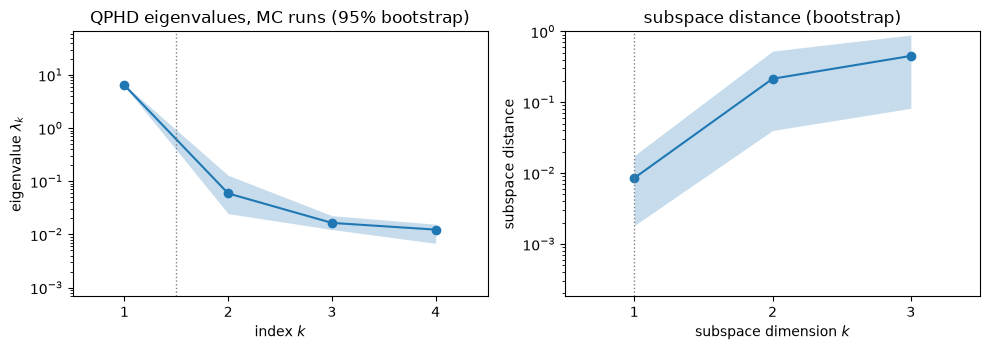

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ac.plotting.plot_eigenvalues(sub, ax=ax[0])
ac.plotting.plot_subspace_errors(sub, ax=ax[1])
ax[0].set_title('QPHD eigenvalues, MC runs (95% bootstrap)')
ax[1].set_title('subspace distance (bootstrap)')
fig.tight_layout()
plt.close(fig)
fig

The eigenvalues fall from $\lambda_1 = 6.376$ to $\lambda_2 = 0.05903$, a ratio of 108.0 with bootstrap
interval [50.3, 256.4]; the next ratio, 3.6 [1.6, 7.7], is far smaller, and $\lambda_2$–$\lambda_4$ hold
0.0136 of the trace. The one-dimensional subspace is stable (mean bootstrap distance 0.0085), while the
two-dimensional one is not (0.2141), because $\lambda_2$ and $\lambda_3$ are not well separated. These
eigenvalues are those of the quadratic that QPHD fits, and that quadratic is a poor fit here (LOO $R^2$ 0.8338,
below): the gap describes the quadratic approximation, which cannot see the steep corner at small $\alpha$.

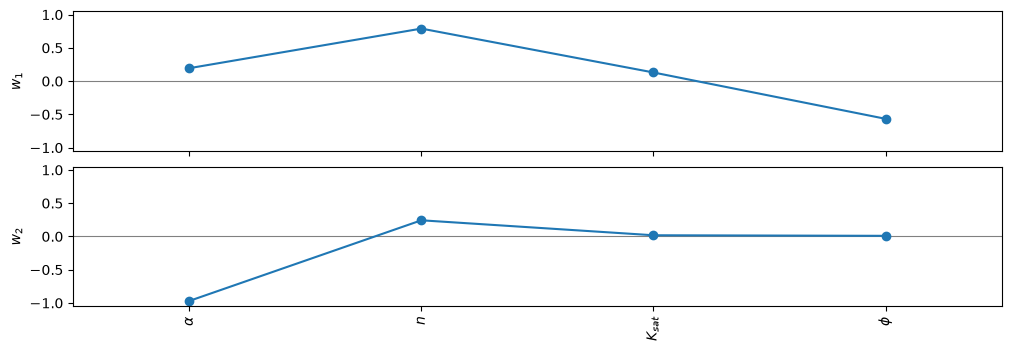

In [6]:
fig, ax = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(10, 3.4))
plt.close(fig)
fig

$w_1 = (0.195, 0.79, 0.13, -0.566)$ for $(\alpha, n, K_{sat}, \phi)$: the RMSE changes mostly along a
combination of $n$ and porosity in opposite directions, with small weights on $\alpha$ and $K_{sat}$.
$w_2 = (-0.97, 0.243, 0.018, 0.009)$ is almost pure $\alpha$.

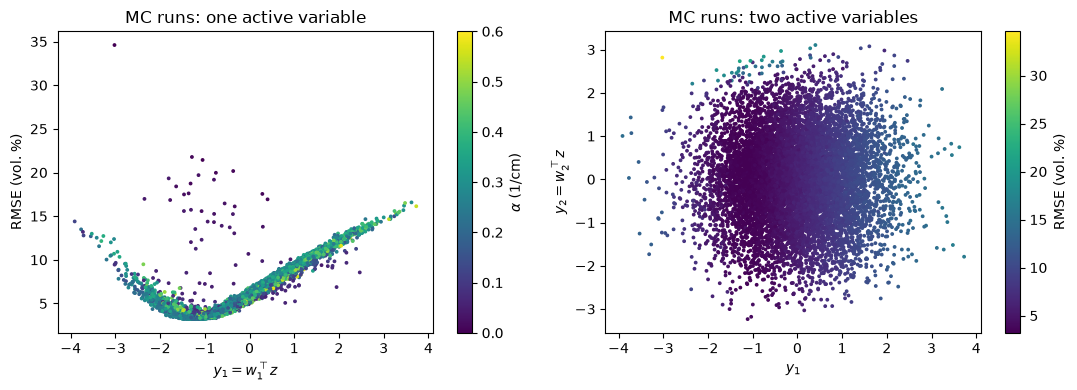

In [7]:
Zm = (Xm - mu) / sd                    # the space's normalized coordinates (each input by its sd)
assert np.allclose(Zm, space.to_normalized(Xm))
y1, y2 = Zm @ sub.W[:, 0], Zm @ sub.W[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(y1, fm, c=Xm[:, 0], s=3, cmap='viridis')
fig.colorbar(sc, ax=ax[0], label=r'$\alpha$ (1/cm)')
ax[0].set_xlabel(r'$y_1 = w_1^\top z$'); ax[0].set_ylabel('RMSE (vol. %)')
ax[0].set_title('MC runs: one active variable')
sc = ax[1].scatter(y1, y2, c=fm, s=3, cmap='viridis')
fig.colorbar(sc, ax=ax[1], label='RMSE (vol. %)')
ax[1].set_xlabel(r'$y_1$'); ax[1].set_ylabel(r'$y_2 = w_2^\top z$')
ax[1].set_title('MC runs: two active variables')
fig.tight_layout()
plt.close(fig)
fig

The RMSE is a V-shaped function of $y_1$ with its minimum near $y_1 \approx -1.2$; along the V the
colour (α) shows no pattern except for a scatter of dark (small-α) points far above it. In the
two-variable plot those runs sit at large $y_2$ (small α).

In [8]:
def loo(X, f, s, deg):
    return ac.fit_surrogate(X=X, f=f, space=space, subspace=s, kind='poly', degree=deg).loo_r_squared

sub2 = ac.with_dimension(sub, 2)
print('LOO R^2 of polynomials in the active variables (MC runs)')
for deg in [2, 4, 6, 8]:
    print(f'  degree {deg}: n = 1 {loo(Xm, fm, sub, deg):.4f}   n = 2 {loo(Xm, fm, sub2, deg):.4f}')
print(f'  all four inputs, degree 4: {loo(Xm, fm, None, 4):.4f}')
Zq = (Xm - mu) / sd
J, K = np.triu_indices(4)
Aq = np.column_stack([np.ones(M), Zq, Zq[:, J] * Zq[:, K]])     # the quadratic QPHD fits (15 terms)
Qq, _ = np.linalg.qr(Aq)
hq = np.sum(Qq ** 2, axis=1)
rq = fm - Qq @ (Qq.T @ fm)
tss = np.sum((fm - fm.mean()) ** 2)
print(f'  full quadratic in the 4 inputs (the QPHD fit): exact LOO R^2 {1 - np.sum((rq / (1 - hq)) ** 2) / tss:.4f}')
small = Xm[:, 0] < 0.05
p_small = stats.norm.cdf((0.05 - 0.3) / 0.1) - stats.norm.cdf(a_lo)
print(f'rows with alpha < 0.05: {small.sum()} of {M} ({small.mean():.4f}); prior probability of '
      f'0.0001 <= alpha < 0.05 under N(0.3, 0.1^2): {p_small:.4f} ({10000 * p_small:.1f} rows expected of 10,000)')
print(f'  their share of the sum of squares of the RMSE about its mean: {np.sum((fm[small] - fm.mean()) ** 2) / tss:.4f}')
print(f'  their RMSE: median {np.median(fm[small]):.2f}, max {fm[small].max():.2f}; others: median {np.median(fm[~small]):.2f}')
print(f'  LOO R^2, n = 1, degree 6, without them: {loo(Xm[~small], fm[~small], sub, 6):.4f}')
sub_big = ac.active_subspace(space=space, X=Xm[~small], f=fm[~small], estimator='qphd', n=1)
e2 = sub_big.eigenvalues
print(f'  QPHD without them: lambda_1/lambda_2 = {e2[0] / e2[1]:.1f}, distance to w1(all) = {np.sqrt(max(1 - (sub_big.W[:, 0] @ sub.W[:, 0]) ** 2, 0)):.1e}')
sub_log = ac.orient(ac.active_subspace(space=space, X=Xm, f=np.log(fm), estimator='qphd', n=1), by='covariance',
                    X=Xm, f=np.log(fm), columns=1)
e3 = sub_log.eigenvalues
print(f'QPHD on log RMSE (all MC rows): lambda_1/lambda_2 = {e3[0] / e3[1]:.1f}, w1 = {np.round(sub_log.W[:, 0], 3)}')

LOO R^2 of polynomials in the active variables (MC runs)
  degree 2: n = 1 0.8262   n = 2 0.8319
  degree 4: n = 1 0.8851   n = 2 0.9424
  degree 6: n = 1 0.8913   n = 2 0.9609


  degree 8: n = 1 0.8912   n = 2 0.9585
  all four inputs, degree 4: 0.9464
  full quadratic in the 4 inputs (the QPHD fit): exact LOO R^2 0.8338
rows with alpha < 0.05: 36 of 9972 (0.0036); prior probability of 0.0001 <= alpha < 0.05 under N(0.3, 0.1^2): 0.0049 (48.6 rows expected of 10,000)
  their share of the sum of squares of the RMSE about its mean: 0.0635
  their RMSE: median 15.93, max 34.60; others: median 6.05
  LOO R^2, n = 1, degree 6, without them: 0.9714


  QPHD without them: lambda_1/lambda_2 = 301.1, distance to w1(all) = 7.8e-03
QPHD on log RMSE (all MC rows): lambda_1/lambda_2 = 167.7, w1 = [ 0.181  0.795  0.128 -0.564]


**Dimension.** The eigenvalue gap of 108.0 comes from a quadratic with LOO $R^2$ 0.8338: a quadratic
cannot follow the steep rise of the RMSE as $\alpha \to 0$. The 36 runs with $\alpha < 0.05$ are 0.0036 of the
MC runs, against a prior probability of 0.0049 for $0.0001 \le \alpha < 0.05$, but they hold 0.0635 of the sum
of squares (median RMSE 15.93 against 6.05). With all MC runs a polynomial in $y_1$ reaches LOO $R^2$ 0.8913
(degree 6) and one in $(y_1, y_2)$ 0.9609. That is above the degree-4 polynomial in all four inputs (0.9464),
and $w_2$ is almost pure $\alpha$. Without the 36 runs the one-variable fit reaches LOO $R^2$ 0.9714, and QPHD on
the remaining runs gives $\lambda_1/\lambda_2 = 301.1$ with nearly the same $w_1$ (subspace distance 7.8e-03).
On log RMSE, which damps the corner, QPHD gives $\lambda_1/\lambda_2 = 167.7$ with
$w_1$ = (0.181, 0.795, 0.128, −0.564).

So the leading direction is robust, and the dimension depends on what the subspace is for. **$n = 1$ for the
bulk of the prior**: one stable direction of $n$ and porosity describes the RMSE wherever $\alpha \ge 0.05$.
**$n = 2$ if the corner matters**: the second, α-only direction carries the steep rise of the RMSE for
$\alpha < 0.05$ 1/cm, and with it a two-variable polynomial explains 0.9609 of the LOO variance against 0.8913.
The notebook's main estimate and plots use $n = 1$ with this caveat. The threshold 0.05 is this data set's
choice, read from the scatter of RMSE against α (LHS plot below); the MC estimate of 108.0 does not depend on
it, since it uses all rows.

In [9]:
with warnings.catch_warnings(record=True) as wlist:
    warnings.simplefilter('always')
    g = ac.local_linear_gradients(X=Xm, f=fm, space=space)
print([str(w.message).split(';')[0] for w in wlist if issubclass(w.category, ac.AccuracyWarning)])
sub_ll = ac.active_subspace(space=space, grads=g, n=1)
el = sub_ll.eigenvalues
print('local linear + AS: eigenvalues', np.round(el, 3), ' ratios', np.round(el[:-1] / el[1:], 2))
print(f'  |w1(local linear) . w1(QPHD)| = {abs(sub_ll.W[:, 0] @ sub.W[:, 0]):.4f}')

['local_linear_gradients: 2614 of 9972 local systems are rank-deficient']
local linear + AS: eigenvalues [9.512 7.054 5.507 3.211]  ratios [1.35 1.28 1.71]
  |w1(local linear) . w1(QPHD)| = 0.9908


**Check with local-linear gradients.** Gradients from local linear fits to nearest neighbours give a
leading direction close to QPHD's ($|w_1^\top w_1^{QPHD}| = 0.9908$) but no eigenvalue gap (ratios 1.35, 1.28,
1.71): 2614 of the 9972 local systems are rank-deficient because the rounded inputs repeat, and the rounding
noise inflates every eigenvalue. This is why QPHD is used.

## The LHS runs as a second design

In [10]:
def angle_info(s, ref):
    return abs(s.W[:, 0] @ ref.W[:, 0])

print('QPHD on the LHS runs, same space (inputs scaled by the MC prior sd)')
res_l = {}
for thr in [None, 0.03, 0.05, 0.10]:
    keep = np.ones(len(Xl), bool) if thr is None else Xl[:, 0] >= thr
    s = ac.active_subspace(space=space, X=Xl[keep], f=fl[keep], estimator='qphd', n=1)
    s = ac.orient(s, by='covariance', X=Xl[keep], f=fl[keep], columns=2)
    res_l[thr] = s
    e = s.eigenvalues
    tag = 'all rows' if thr is None else f'alpha >= {thr:.2f}'
    print(f'  {tag:14s} M = {keep.sum():5d}  ratios {np.round(e[:-1] / e[1:], 1)}  w1 {np.round(s.W[:, 0], 3)}'
          f'  |w1 . w1(MC)| {angle_info(s, sub):.4f}  w2 {np.round(s.W[:, 1], 3)}')
keep = Xl[:, 0] >= 0.05
print(f'  LHS rows with alpha < 0.05: {np.sum(Xl[:, 0] < 0.05)} of {len(Xl)}')
print(f'  LOO R^2 (degree 6, MC w1): all LHS rows {loo(Xl, fl, sub, 6):.4f}; alpha >= 0.05 {loo(Xl[keep], fl[keep], sub, 6):.4f}')
print(f'  LOO R^2 (degree 6, two LHS directions, all rows): {loo(Xl, fl, ac.with_dimension(res_l[None], 2), 6):.4f}')
# The same quadratic fits, with C averaged over the LHS points themselves instead of the Gaussian prior.
Zl0 = (Xl - mu) / sd
print('QPHD quadratic on the LHS runs, C averaged over the LHS points (the design density), same coordinates')
for thr in [None, 0.05]:
    keep = np.ones(len(Xl), bool) if thr is None else Xl[:, 0] >= thr
    Zk = Zl0[keep]
    A = np.column_stack([np.ones(len(Zk)), Zk, Zk[:, J] * Zk[:, K]])
    c = np.linalg.lstsq(A, fl[keep], rcond=None)[0]
    H = np.zeros((4, 4))
    for v, j, k in zip(c[5:], J, K):
        H[j, k] += v
        H[k, j] += v                                   # so that the gradient is g + H z
    Gk = c[1:5] + Zk @ H
    e = np.sort(np.linalg.eigvalsh(Gk.T @ Gk / len(Gk)))[::-1]
    tag = 'all rows' if thr is None else f'alpha >= {thr:.2f}'
    print(f'  {tag:14s} ratios {np.round(e[:-1] / e[1:], 1)}')

QPHD on the LHS runs, same space (inputs scaled by the MC prior sd)
  all rows       M =  9978  ratios [ 2.6 84.1  5.3]  w1 [ 0.489  0.702  0.077 -0.511]  |w1 . w1(MC)| 0.9498  w2 [-0.835  0.515  0.181 -0.065]
  alpha >= 0.03  M =  9542  ratios [15.5 18.6  2.7]  w1 [ 0.256  0.802  0.114 -0.527]  |w1 . w1(MC)| 0.9971  w2 [-0.865  0.355  0.304  0.186]
  alpha >= 0.05  M =  9191  ratios [202.2   2.7  46.7]  w1 [ 0.227  0.813  0.116 -0.523]  |w1 . w1(MC)| 0.9982  w2 [0.359 0.241 0.609 0.665]
  alpha >= 0.10  M =  8314  ratios [107.7   4.6   3.6]  w1 [ 0.199  0.818  0.115 -0.527]  |w1 . w1(MC)| 0.9987  w2 [-0.951  0.144 -0.206 -0.18 ]
  LHS rows with alpha < 0.05: 787 of 9978
  LOO R^2 (degree 6, MC w1): all LHS rows 0.4921; alpha >= 0.05 0.9140
  LOO R^2 (degree 6, two LHS directions, all rows): 0.8660
QPHD quadratic on the LHS runs, C averaged over the LHS points (the design density), same coordinates
  all rows       ratios [  3.8 102.4   2.6]
  alpha >= 0.05  ratios [273.2   1.7  55.4]


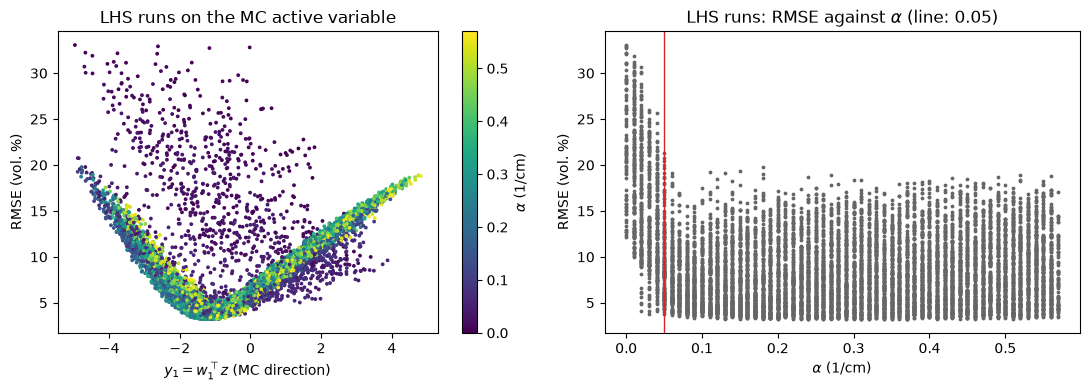

In [11]:
Zl = (Xl - mu) / sd
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(Zl @ sub.W[:, 0], fl, c=Xl[:, 0], s=3, cmap='viridis')
fig.colorbar(sc, ax=ax[0], label=r'$\alpha$ (1/cm)')
ax[0].set_xlabel(r'$y_1 = w_1^\top z$ (MC direction)'); ax[0].set_ylabel('RMSE (vol. %)')
ax[0].set_title('LHS runs on the MC active variable')
ax[1].scatter(Xl[:, 0], fl, s=3, c='0.4')
ax[1].axvline(0.05, color='C3', lw=1)
ax[1].set_xlabel(r'$\alpha$ (1/cm)'); ax[1].set_ylabel('RMSE (vol. %)')
ax[1].set_title(r'LHS runs: RMSE against $\alpha$ (line: 0.05)')
fig.tight_layout()
plt.close(fig)
fig

On all LHS runs QPHD gives two directions (ratios 2.6 then 84.1), the second again mostly α
(−0.835 for α), and a polynomial in the MC $y_1$ explains only LOO $R^2$ 0.4921 of the RMSE (0.8660 with the two
LHS directions). With $\alpha \ge 0.05$ (9191 runs) the LHS runs give one direction, $\lambda_1/\lambda_2 =
202.2$, with $|w_1^\top w_1^{MC}| = 0.9982$, and the MC $y_1$ explains LOO $R^2$ 0.9140. The ratio depends on
the threshold. It is 15.5 at 0.03, 202.2 at 0.05 and 107.7 at 0.10. At 0.05 the later ratios are 2.7 and 46.7,
so 202.2 is the peak of this scan and is not a stable value. These QPHD numbers mix two densities: the quadratic
is fitted by least squares to the uniform LHS box, but $\mathbf{C}$ is averaged under the Gaussian prior (the
space of the MC runs). Averaging the same quadratics over the LHS points instead gives ratios 3.8, 102.4
(all rows) and 273.2 (α ≥ 0.05). The numbers change, but the conclusion does not: the second direction comes
from where the LHS design puts its points, the small-α corner, not from the prior. The left plot shows the same V
as the MC runs plus the small-α runs above it; the right plot shows the steep rise of the RMSE below α ≈ 0.05.

## A one-variable surrogate

degree-6 polynomial in y1, MC runs: LOO R^2 = 0.8913
polynomial minimum 3.631 at y1 = -1.203


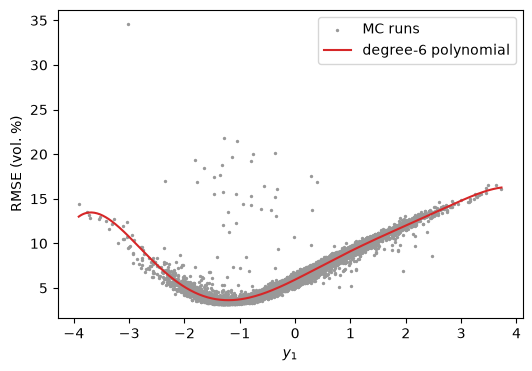

In [12]:
sur = ac.fit_surrogate(X=Xm, f=fm, space=space, subspace=sub, kind='poly', degree=6)
print(f'degree-6 polynomial in y1, MC runs: LOO R^2 = {sur.loo_r_squared:.4f}')
yy = np.linspace(y1.min(), y1.max(), 300)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(y1, fm, s=2, c='0.6', label='MC runs')
ax.plot(yy, sur.evaluate(yy), 'C3', label='degree-6 polynomial')
ax.set_xlabel(r'$y_1$'); ax.set_ylabel('RMSE (vol. %)'); ax.legend()
i_min = np.argmin(sur.evaluate(yy))
print(f'polynomial minimum {sur.evaluate(yy)[i_min]:.3f} at y1 = {yy[i_min]:.3f}')
plt.close(fig)
fig

The degree-6 polynomial in $y_1$ has LOO $R^2$ 0.8913 on the MC runs; its minimum, 3.631 vol. % at
$y_1 = -1.203$, lies above the best runs (3.21) because it averages over the V's width, which comes from the
other three directions, from the input rounding and from the small-α runs.

## Comparison with the paper

In [13]:
for lab, X, f in [('MC', Xm, fm), ('LHS', Xl, fl)]:
    best = f == f.min()
    print(f'{lab}: best stored RMSE {f.min():.2f} in {best.sum()} rows:')
    for row in X[best]:
        print('    alpha {:.2f}  n {:.2f}  ksat {:.2f}  porosity {:.2f}'.format(*row))
top = fm <= np.quantile(fm, 0.10)
print(f'MC best 10% ({top.sum()} rows): sd / prior sd per input',
      np.round(Xm[top].std(0, ddof=1) / sd, 3), f'; sd of y1 {y1[top].std(ddof=1):.3f} (all rows {y1.std(ddof=1):.3f})')
print('MC best 10%: range per input', [f'{nm} [{Xm[top, j].min():.2f}, {Xm[top, j].max():.2f}]' for j, nm in enumerate(names)])

MC: best stored RMSE 3.21 in 3 rows:
    alpha 0.30  n 1.18  ksat 1.33  porosity 0.62
    alpha 0.25  n 1.18  ksat 0.79  porosity 0.59
    alpha 0.28  n 1.18  ksat 1.24  porosity 0.60
LHS: best stored RMSE 3.22 in 3 rows:
    alpha 0.41  n 1.17  ksat 1.86  porosity 0.63
    alpha 0.13  n 1.19  ksat 0.19  porosity 0.55
    alpha 0.30  n 1.17  ksat 1.19  porosity 0.60
MC best 10% (1018 rows): sd / prior sd per input [0.828 0.473 0.999 0.711] ; sd of y1 0.212 (all rows 0.992)
MC best 10%: range per input ['alpha [0.09, 0.54]', 'n [1.13, 1.22]', 'ksat [0.14, 1.94]', 'porosity [0.51, 0.67]']


| quantity | paper (page) | this notebook |
|---|---|---|
| active subspace, eigenvalues | not reported | $\lambda_1/\lambda_2 = 108.0$ [50.3, 256.4] (MC, QPHD; its quadratic has LOO $R^2$ 0.8338); $n = 1$ for the bulk of the prior, $n = 2$ (second direction α) for the corner α < 0.05 |
| best RMSE, all algorithms | 3.2096 (ROPE, SCE-UA, MLE); others 3.2098–3.2153 (p. 13) | MC 3.21 (3 runs tie), LHS 3.22 (3 runs) at the stored 2 decimals |
| optimal ksat | "from 0.8 (MLE) to 1.9 (MC)" (text, p. 13); Fig. 9 draws MC's line near 0.8 and MLE's near 1.95 (p. 14) | MC runs tied at 3.21: ksat 1.33, 0.79, 1.24 |
| optimal porosity | 0.6–0.63 for all algorithms (p. 13) | MC best 0.62, 0.59, 0.60; LHS 0.63, 0.55, 0.60 |
| posterior (best 10 %) | MCMC and DE-MCZ narrow n by over 90 % and ksat by 20 %; "the other algorithms failed in reducing the parameter ranges" (p. 13) | MC best 10 %: sd / prior sd 0.828 (α), 0.473 (n), 0.999 (ksat), 0.711 (φ); sd of $y_1$ 0.212 against 0.992 |
| equifinality | "high equifinality of the model" (p. 13) | the best runs lie along the 3-dimensional level set of $y_1$; ksat has weight 0.13 in $w_1$ |
| number of runs | 10,000 iterations per sampler (p. 13; S4 description, p. 18) | 10,001 rows per file, no `optguess` row |

The text and Fig. 9 disagree on which algorithm found ksat 0.8 and which 1.9; the stored MC run with ksat
0.79 (α 0.25, n 1.18, φ 0.59) matches the MC red lines of Fig. 9 in all four panels as read, so the text
appears to swap MC and MLE. Which of the three tied MC runs is best at more decimals cannot be told from the
deposit. The best-10 % selection shrinks $y_1$ to about a fifth of its spread but leaves ksat at its prior
spread, consistent with its small weight in $w_1$.

In [14]:
print(f'run time {time.perf_counter() - t_start:.1f} s')

run time 14.0 s


## References

- T. Houska, P. Kraft, A. Chamorro-Chavez, L. Breuer. SPOTting Model Parameters Using a Ready-Made Python
  Package. *PLOS ONE* 10(12):e0145180, 2015.
  [doi:10.1371/journal.pone.0145180](https://doi.org/10.1371/journal.pone.0145180). Data: supporting file S4,
  [doi:10.1371/journal.pone.0145180.s004](https://doi.org/10.1371/journal.pone.0145180.s004) (CC BY 4.0).
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- K.-C. Li. On Principal Hessian Directions for Data Visualization and Dimension Reduction: Another
  Application of Stein's Lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992.
  [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).
- P. Kraft, K. B. Vaché, H.-G. Frede, L. Breuer. CMF: A Hydrological Programming Language Extension For
  Integrated Catchment Models. *Environmental Modelling & Software* 26(6):828–830, 2011.
  [doi:10.1016/j.envsoft.2010.12.009](https://doi.org/10.1016/j.envsoft.2010.12.009).
- M. Th. van Genuchten. A Closed-form Equation for Predicting the Hydraulic Conductivity of Unsaturated
  Soils. *Soil Science Society of America Journal* 44(5):892–898, 1980.
  [doi:10.2136/sssaj1980.03615995004400050002x](https://doi.org/10.2136/sssaj1980.03615995004400050002x).
- SPOTPY 1.0.13 (PyPI, 2015-09-25, MIT licence): `spotpy/examples/spot_setup_cmf1d.py` and
  `spotpy/algorithms/lhs.py`, read for the example priors, bounds and the LHS construction.

## Acknowledgments

From the paper: this work was funded by the LOEWE excellence cluster FACE2FACE of the Hessen State Ministry
of Higher Education, Research and the Arts. Further support was received by the DFG for Tobias Houska
(BR2238/13-1) and Alejandro Chamorro-Chavez (BR2238/5 2). Lutz Breuer acknowledges funding of the Marie Curie
Training Network: Quantifying Uncertainty in Integrated Catchment Studies (QUICS), PITN-GA-2013-607000. The
authors thank Christoph Müller and Ludger Grünhage for providing the dataset of the FACE project (p. 18), the
forcing and observations behind every run. The runs are the authors' (PLOS ONE supporting information, CC BY
4.0); this notebook only analyses them.